# II.A.1 — Stationarity tests and ARMA–GARCH models of calm-period returns

**Objective (brief II.A.1).** For 10 pump targets in a calm period, (i) test stationarity and serial dependence
with the ADF, KPSS and Ljung–Box tests, and (ii) fit an ARMA$(p,q)$–GARCH(1,1) model with Student-$t$ innovations:
$$r_t=\mu+\sum_{i=1}^{p}\phi_i r_{t-i}+\varepsilon_t+\sum_{j=1}^{q}\theta_j\varepsilon_{t-j},\qquad
\varepsilon_t=\sigma_t\eta_t,\qquad \sigma_t^2=\omega+\alpha\varepsilon_{t-1}^2+\beta\sigma_{t-1}^2,$$
with $\eta_t$ i.i.d. standardised Student-$t_\nu$ ($\mathbb E\eta_t=0$, $\operatorname{Var}\eta_t=1$). These models
describe "normal" behaviour; II.A.2 uses their standardised residuals $\hat\eta_t$ to detect pumps.

**Calm period.** For a pump at $\tau$ we use the hourly log-returns (in %) on $[\tau-30\,\text{d},\ \tau-72\,\text{h}]$,
the estimation window of I.3, which ends before the pre-pump drift.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from arch import arch_model

from pnd_paper import settings, tsmodels
from pnd_paper.data import pd_log, binance, universe
from pnd_paper.report import Reporter, md, show, close, SERIES

warnings.filterwarnings("ignore")
settings.seed_everything()
R = Reporter("IIA1_arma_garch")

ev_all = pd_log.binance_btc_events()
panels = binance.build_hourly_panel(universe.universe(ev_all) + ["BTCUSDT"], universe.PANEL_START, universe.PANEL_END)
close_ = panels["close"]


def calm_window(e):
    t = universe.last_bar_before(e.timestamp)
    s = close_[e.symbol].loc[t - pd.Timedelta(days=30):t - pd.Timedelta(hours=72)]
    return s


# choose 10 distinct coins with complete calm windows (seeded draw among eligible events)
rng = np.random.default_rng(settings.SEED)
cands = []
for e in ev_all.drop_duplicates("symbol").itertuples():
    if e.symbol in close_.columns:
        s = calm_window(e)
        if len(s) > 600 and s.notna().mean() > 0.99 and (s.diff() != 0).mean() > 0.9:
            cands.append(e)
chosen = [cands[i] for i in sorted(rng.choice(len(cands), settings.SIZES.garch_targets, replace=False))]
series = {e.coin: 100 * np.log(calm_window(e)).diff().dropna() for e in chosen}
info = pd.DataFrame([{"coin": e.coin, "pump time": f"{e.timestamp:%Y-%m-%d %H:%M}", "calm window": f"{s.index[0]:%Y-%m-%d} → {s.index[-1]:%Y-%m-%d}",
                      "n": len(s), "mean (%)": s.mean(), "sd (%)": s.std(), "skew": st.skew(s), "excess kurtosis": st.kurtosis(s)}
                     for e, s in zip(chosen, series.values())]).set_index("coin")
R.table(info, "targets")
show(info)
md(f"{len(cands)} target coins have a complete, actively traded calm window; 10 are drawn at random (seed "
   f"{settings.SEED}). Every series has a large excess kurtosis, which motivates Student-$t$ innovations.")

,pump time,calm window,n,mean (%),sd (%),skew,excess kurtosis
coin,,,,,,,
GXS,2019-01-20 17:59,2018-12-21 → 2019-01-17,648,0.01262,0.7278,0.1134,5.509
WINGS,2019-01-27 18:00,2018-12-28 → 2019-01-24,648,0.03826,1.924,7.136,101.1
GRS,2019-02-02 18:00,2019-01-03 → 2019-01-30,648,-0.01188,0.7893,-0.2981,6.948
AST,2019-03-02 14:00,2019-01-31 → 2019-02-27,648,0.02714,1.368,1.624,20.47
ONT,2019-03-21 03:25,2019-02-19 → 2019-03-18,641,0.07022,1.476,1.112,7.717
RDN,2019-03-24 18:59,2019-02-22 → 2019-03-21,641,0.03261,1.683,3.615,38.58
WRX,2021-04-04 15:21,2021-03-05 → 2021-04-01,646,0.1598,2.26,1.881,13.64
CFX,2021-05-12 17:18,2021-04-12 → 2021-05-09,641,-0.03606,1.74,1.624,14.48
ACM,2021-06-05 18:00,2021-05-06 → 2021-06-02,648,0.01573,3.433,0.9148,10.04


58 target coins have a complete, actively traded calm window; 10 are drawn at random (seed 1234). Every series has a large excess kurtosis, which motivates Student-$t$ innovations.

## 1. Tests

* **ADF** (augmented Dickey–Fuller). Regression $\Delta y_t=c+\gamma y_{t-1}+\sum_{k=1}^{K}\delta_k\Delta y_{t-k}+u_t$;
  $H_0:\gamma=0$ (unit root) against $H_1:\gamma<0$ (stationary). The statistic $\hat\gamma/\mathrm{se}(\hat\gamma)$
  follows the Dickey–Fuller distribution; $K$ is chosen by AIC.
* **KPSS**. $y_t=\xi_t+u_t$ with a random walk $\xi_t$ of variance $\sigma^2_\xi$; $H_0:\sigma^2_\xi=0$
  (level-stationary). Statistic $\eta=T^{-2}\sum_t S_t^2/\hat\lambda^2$ with $S_t$ the partial sums of residuals and
  $\hat\lambda^2$ a Newey–West long-run variance. ADF and KPSS have opposite null hypotheses, so stationarity is
  supported when ADF rejects **and** KPSS does not.
* **Ljung–Box**. $Q(m)=T(T+2)\sum_{k=1}^{m}\hat\rho_k^2/(T-k)\overset{H_0}{\sim}\chi^2_m$, $H_0$: no autocorrelation
  up to lag $m$. Applied to $r_t$ (linear dependence, i.e. the ARMA part) and to $r_t^2$ (volatility clustering,
  i.e. the GARCH part), with $m=24$ hours.
* **ARCH-LM** (Engle). Regression of $\hat u_t^2$ on $m$ of its lags; $TR^2\overset{H_0}{\sim}\chi^2_m$, $H_0$: no
  ARCH effect.

In [2]:
rows = []
for coin, r in series.items():
    lp = np.log(close_[[e for e in chosen if e.coin == coin][0].symbol].loc[r.index])
    adf_p = adfuller(lp, autolag="AIC")
    adf_r = adfuller(r, autolag="AIC")
    kp_p = kpss(lp, regression="c", nlags="auto")
    kp_r = kpss(r, regression="c", nlags="auto")
    lb = acorr_ljungbox(r, lags=[24])
    lb2 = acorr_ljungbox(r**2, lags=[24])
    arch_lm = het_arch(r - r.mean(), nlags=12)
    rows.append({"coin": coin, "ADF log-price": adf_p[0], "p ADF log-price": adf_p[1], "ADF r": adf_r[0], "p ADF r": adf_r[1],
                 "KPSS log-price": kp_p[0], "p KPSS log-price": kp_p[1], "KPSS r": kp_r[0], "p KPSS r": kp_r[1],
                 "Q(24) r": lb.lb_stat.iloc[0], "p Q r": lb.lb_pvalue.iloc[0], "Q(24) r^2": lb2.lb_stat.iloc[0],
                 "p Q r^2": lb2.lb_pvalue.iloc[0], "ARCH-LM(12)": arch_lm[0], "p ARCH": arch_lm[1]})
tests = pd.DataFrame(rows).set_index("coin")
R.table(tests, "stationarity_tests")
show(tests, "{:.3g}")
md("**Reading the table.** statsmodels truncates KPSS p-values to [0.01, 0.10] (values printed as 0.01 or 0.1 mean "
   "'at most' / 'at least').\n\n"
   f"- Log-prices: ADF rejects the unit root for {(tests['p ADF log-price'] < 0.05).sum()}/10 coins and KPSS rejects "
   f"level-stationarity for {(tests['p KPSS log-price'] < 0.05).sum()}/10.\n"
   f"- Returns: ADF rejects the unit root for {(tests['p ADF r'] < 0.05).sum()}/10 coins, KPSS rejects stationarity for "
   f"{(tests['p KPSS r'] < 0.05).sum()}/10.\n"
   f"- Ljung–Box on $r_t$ rejects 'no autocorrelation' for {(tests['p Q r'] < 0.05).sum()}/10 coins; on $r_t^2$ for "
   f"{(tests['p Q r^2'] < 0.05).sum()}/10; ARCH-LM detects ARCH effects for {(tests['p ARCH'] < 0.05).sum()}/10.")

,ADF log-price,p ADF log-price,ADF r,p ADF r,KPSS log-price,p KPSS log-price,KPSS r,p KPSS r,Q(24) r,p Q r,Q(24) r^2,p Q r^2,ARCH-LM(12),p ARCH
coin,,,,,,,,,,,,,,
GXS,-2.34,0.16,-11.1,3.35e-20,0.276,0.1,0.038,0.1,57.8,0.000128,112,2.36e-13,57.1,7.49e-08
WINGS,-1.66,0.452,-5.97,1.99e-07,1.92,0.01,0.073,0.1,68.5,3.63e-06,147,1.34e-19,132,2.34e-22
GRS,-2.35,0.156,-12.9,3.88e-24,0.384,0.0838,0.0497,0.1,38.4,0.0313,181,3.88e-26,78.1,9.38e-12
AST,-1.95,0.309,-14.8,2.19e-27,2.56,0.01,0.0523,0.1,38.9,0.028,66.5,7.32e-06,58.3,4.65e-08
ONT,-2.26,0.187,-6.12,8.81e-08,1.92,0.01,0.163,0.1,60.8,4.91e-05,298,4.53e-49,138,1.2e-23
RDN,-1.95,0.307,-5.13,1.22e-05,2.64,0.01,0.0449,0.1,122,5.22e-15,150,2.76e-20,18.1,0.114
WRX,0.447,0.983,-6.21,5.65e-08,2.82,0.01,0.201,0.1,93.1,4.43e-10,227,5.35e-35,56.7,9.1e-08
CFX,-2,0.288,-8.42,1.99e-13,1.78,0.01,0.0412,0.1,63.5,2.04e-05,40.7,0.0178,32.7,0.00108
ACM,-1.76,0.4,-10.3,3.27e-18,0.76,0.01,0.165,0.1,50.6,0.0012,107,2.18e-12,62.9,6.69e-09


**Reading the table.** statsmodels truncates KPSS p-values to [0.01, 0.10] (values printed as 0.01 or 0.1 mean 'at most' / 'at least').

- Log-prices: ADF rejects the unit root for 0/10 coins and KPSS rejects level-stationarity for 8/10.
- Returns: ADF rejects the unit root for 10/10 coins, KPSS rejects stationarity for 0/10.
- Ljung–Box on $r_t$ rejects 'no autocorrelation' for 9/10 coins; on $r_t^2$ for 9/10; ARCH-LM detects ARCH effects for 8/10.

## 2. ARMA$(p,q)$–GARCH(1,1)–$t$ estimation

**Estimation.** Parameters $\psi=(\mu,\phi,\theta,\omega,\alpha,\beta,\nu)$ maximise the conditional log-likelihood
$$\ell(\psi)=\sum_{t}\Big[\log\Gamma\big(\tfrac{\nu+1}{2}\big)-\log\Gamma\big(\tfrac{\nu}{2}\big)-\tfrac12\log\big(\pi(\nu-2)\big)
-\log\sigma_t-\tfrac{\nu+1}{2}\log\Big(1+\frac{\eta_t^2}{\nu-2}\Big)\Big],\quad \eta_t=\varepsilon_t/\sigma_t,$$
under $\omega>0$, $\alpha,\beta\ge0$, $\alpha+\beta<1$ (covariance stationarity) and $\nu>2$. Standard errors come
from the inverse numerical Hessian, $\widehat{\operatorname{Var}}(\hat\psi)=[-\nabla^2\ell(\hat\psi)]^{-1}$. The
estimator is written from scratch (`pnd_paper.tsmodels`) because the `arch` package only offers AR means; we
validate it against `arch` on the AR(1) special case.

**Order selection.** $p,q\in\{0,1,2,3\}$ (16 models per coin), chosen by
$\mathrm{BIC}=-2\ell(\hat\psi)+k\log n$.

In [3]:
coin0 = next(iter(series))
f_ours = tsmodels.fit_arma_garch(series[coin0].values, 1, 0)
f_arch = arch_model(series[coin0].values, mean="AR", lags=1, vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
val = pd.DataFrame({"pnd_paper": [f_ours.params[k] for k in ("mu", "phi1", "omega", "alpha", "beta", "nu")] + [f_ours.loglik],
                    "arch package": list(f_arch.params.values) + [f_arch.loglikelihood]},
                   index=["mu", "phi1", "omega", "alpha", "beta", "nu", "log-likelihood"])
R.table(val, "validation_vs_arch")
show(val)
md(f"Validation on {coin0}, AR(1)–GARCH(1,1)–t: both estimators reach the same log-likelihood up to "
   f"{abs(f_ours.loglik - f_arch.loglikelihood):.2f} (flat likelihood in the $(\\omega,\\alpha,\\beta)$ direction explains small "
   "parameter differences).")

,pnd_paper,arch package
mu,0.01367,0.01392
phi1,-0.1761,-0.1761
omega,0.06829,0.06845
alpha,0.3894,0.3887
beta,0.6105,0.6113
nu,3.147,3.137
log-likelihood,-575.4,-575.4


Validation on GXS, AR(1)–GARCH(1,1)–t: both estimators reach the same log-likelihood up to 0.03 (flat likelihood in the $(\omega,\alpha,\beta)$ direction explains small parameter differences).

In [4]:
fits, grids = {}, {}
for coin, r in series.items():
    best, grid = tsmodels.select_arma_garch(r.values, 3, 3, "bic")
    fits[coin] = best
    grids[coin] = pd.DataFrame(grid)
param_rows = []
for coin, f in fits.items():
    row = {"coin": coin, "order": f"ARMA({f.p},{f.q})"}
    for k in ("mu", "omega", "alpha", "beta", "nu"):
        row[k] = f.params[k]
        row[f"se({k})"] = f.se[k]
    row["alpha+beta"] = f.persistence
    row["half-life (h)"] = np.log(0.5) / np.log(f.persistence) if f.persistence < 1 else np.inf
    row["BIC"] = f.bic
    param_rows.append(row)
params = pd.DataFrame(param_rows).set_index("coin")
R.table(params, "garch_parameters")
show(params, "{:.4g}")
at_bound = int((params["alpha+beta"] > 0.999).sum())
interior = params.loc[params["alpha+beta"] <= 0.999]
md(f"Selected orders: {', '.join(f'{c}: ARMA({f.p},{f.q})' for c, f in fits.items())}.\n\n"
   f"Persistence: for **{at_bound}/10** coins the estimate sits on the stationarity boundary "
   f"$\\hat\\alpha+\\hat\\beta\\approx1$ (integrated-GARCH behaviour: a volatility shock does not decay within the "
   f"30-day window); for the other {len(interior)} coins $\\hat\\alpha+\\hat\\beta$ ranges from "
   f"{interior['alpha+beta'].min():.2f} to {interior['alpha+beta'].max():.2f} (half-lives "
   f"{interior['half-life (h)'].min():.0f}–{interior['half-life (h)'].max():.0f} h). Median "
   f"$\\hat\\nu={params['nu'].median():.1f}$, i.e. very heavy tails (the kurtosis of $t_\\nu$ is infinite for $\\nu\\le4$).")

,order,mu,se(mu),omega,se(omega),alpha,se(alpha),beta,se(beta),nu,se(nu),alpha+beta,half-life (h),BIC
coin,,,,,,,,,,,,,,
GXS,"ARMA(0,1)",0.01078,0.01378,0.06601,0.02494,0.3868,0.1177,0.6131,0.07509,3.164,0.4559,0.9999,6966,1186
WINGS,"ARMA(0,1)",-0.01263,0.01822,0.09393,0.04106,0.1813,0.07853,0.8186,0.05663,2.365,0.1772,0.9999,7350,1458
GRS,"ARMA(0,1)",-0.009522,0.01649,0.05207,0.03117,0.1236,0.05219,0.8119,0.07721,3.273,0.4718,0.9355,10.39,1326
AST,"ARMA(1,1)",-0.0005113,0.0006932,0.02435,0.01101,0.1139,0.02805,0.886,0.02511,2.939,0.2938,0.9999,1.062e+04,1754
ONT,"ARMA(0,1)",-0.05085,0.02947,0.08682,0.04473,0.1045,0.04627,0.8867,0.03499,2.765,0.3555,0.9913,78.97,2024
RDN,"ARMA(2,1)",-0.0002722,0.001129,0.9238,0.4682,0.5,0.2552,0.4999,0.1398,2.24,0.1198,0.9999,7051,1810
WRX,"ARMA(2,0)",-0.04298,0.05074,0.05046,0.03216,0.1037,0.02765,0.8962,0.02519,3.843,0.5427,0.9999,7808,2553
CFX,"ARMA(1,2)",-0.2829,0.06337,0.1248,0.06553,0.07125,0.03044,0.902,0.03228,2.894,0.3603,0.9733,25.59,2269
ACM,"ARMA(0,2)",-0.09081,0.03886,0.09348,0.04049,0.1191,0.02882,0.8808,0.02791,3.056,0.3211,0.9999,1.165e+04,2890


Selected orders: GXS: ARMA(0,1), WINGS: ARMA(0,1), GRS: ARMA(0,1), AST: ARMA(1,1), ONT: ARMA(0,1), RDN: ARMA(2,1), WRX: ARMA(2,0), CFX: ARMA(1,2), ACM: ARMA(0,2), BZRX: ARMA(1,0).

Persistence: for **6/10** coins the estimate sits on the stationarity boundary $\hat\alpha+\hat\beta\approx1$ (integrated-GARCH behaviour: a volatility shock does not decay within the 30-day window); for the other 4 coins $\hat\alpha+\hat\beta$ ranges from 0.70 to 0.99 (half-lives 2–79 h). Median $\hat\nu=3.0$, i.e. very heavy tails (the kurtosis of $t_\nu$ is infinite for $\nu\le4$).

In [5]:
grid_all = pd.concat({c: g for c, g in grids.items()}, names=["coin"]).reset_index(level=0)
best_counts = grid_all.loc[grid_all.groupby("coin").BIC.idxmin(), ["p", "q"]].value_counts().rename("coins").reset_index()
show(best_counts.set_index(["p", "q"]))

## 3. Residual diagnostics

If the model is adequate, $\hat\eta_t$ is i.i.d. with the fitted $t_\nu$ law: no autocorrelation in $\hat\eta_t$
(Ljung–Box), no remaining ARCH effect in $\hat\eta_t^2$, and a Kolmogorov–Smirnov test of $\hat\eta_t$ against the
standardised $t_{\hat\nu}$ should not reject (the KS p-value is approximate because $\nu$ is estimated).

In [6]:
diag = []
for coin, f in fits.items():
    lb = acorr_ljungbox(f.eta, lags=[24], model_df=f.p + f.q)
    lb2 = acorr_ljungbox(f.eta**2, lags=[24], model_df=2)
    nu = f.params["nu"]
    ks = st.kstest(f.eta, lambda x, nu=nu: st.t.cdf(x * np.sqrt(nu / (nu - 2)), nu))
    diag.append({"coin": coin, "Q(24) eta": lb.lb_stat.iloc[0], "p": lb.lb_pvalue.iloc[0], "Q(24) eta^2": lb2.lb_stat.iloc[0],
                 "p ": lb2.lb_pvalue.iloc[0], "KS vs t_nu": ks.statistic, "p KS": ks.pvalue})
diag = pd.DataFrame(diag).set_index("coin")
R.table(diag, "residual_diagnostics")
show(diag, "{:.3g}")
md(f"Ljung–Box on $\\hat\\eta_t$ does not reject at 5 % for {(diag['p'] >= 0.05).sum()}/10 coins, on $\\hat\\eta_t^2$ for "
   f"{(diag['p '] >= 0.05).sum()}/10 coins, and the KS test does not reject the $t_\\nu$ law for "
   f"{(diag['p KS'] >= 0.05).sum()}/10 coins.")

,Q(24) eta,p,Q(24) eta^2,p,KS vs t_nu,p KS
coin,,,,,,
GXS,20.5,0.611,25.2,0.288,0.0311,0.548
WINGS,15.3,0.884,15,0.862,0.0293,0.624
GRS,26.4,0.28,9.28,0.992,0.0255,0.783
AST,17.8,0.719,7.28,0.999,0.0289,0.639
ONT,30.7,0.131,21.7,0.475,0.0365,0.353
RDN,47.3,0.000859,25,0.296,0.0437,0.169
WRX,29.1,0.143,20.5,0.553,0.0361,0.361
CFX,28.1,0.136,13.5,0.918,0.0335,0.459
ACM,30.8,0.1,5.58,1,0.035,0.398


Ljung–Box on $\hat\eta_t$ does not reject at 5 % for 9/10 coins, on $\hat\eta_t^2$ for 10/10 coins, and the KS test does not reject the $t_\nu$ law for 10/10 coins.

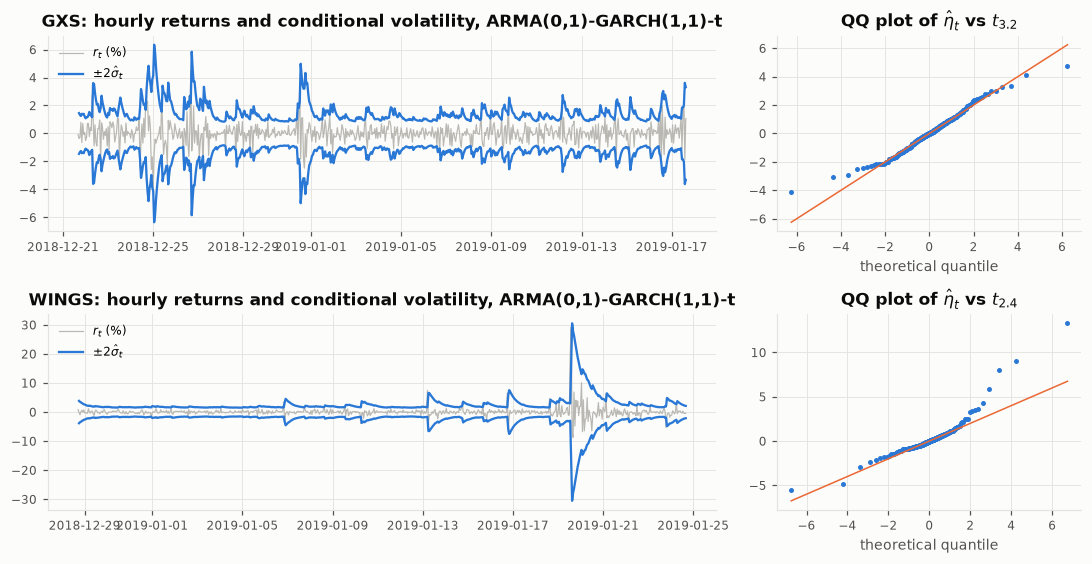

In [7]:
two = list(series)[:2]
fig, axes = plt.subplots(2, 2, figsize=(10, 5.2), gridspec_kw={"width_ratios": [2.2, 1]})
for i, coin in enumerate(two):
    r = series[coin]
    f = fits[coin]
    idx = r.index[-len(f.sigma):]
    axes[i, 0].plot(r.index, r.values, color="#b9b8b2", lw=0.8, label="$r_t$ (%)")
    axes[i, 0].plot(idx, 2 * f.sigma, color=SERIES[0], lw=1.5, label=r"$\pm2\hat\sigma_t$")
    axes[i, 0].plot(idx, -2 * f.sigma, color=SERIES[0], lw=1.5)
    axes[i, 0].set_title(f"{coin}: hourly returns and conditional volatility, ARMA({f.p},{f.q})-GARCH(1,1)-t")
    axes[i, 0].legend(loc="upper left")
    nu = f.params["nu"]
    q_th = st.t.ppf((np.arange(1, len(f.eta) + 1) - 0.5) / len(f.eta), nu) * np.sqrt((nu - 2) / nu)
    axes[i, 1].scatter(q_th, np.sort(f.eta), s=5, color=SERIES[0])
    lim = [q_th.min(), q_th.max()]
    axes[i, 1].plot(lim, lim, color=SERIES[1], lw=1)
    axes[i, 1].set_title(f"QQ plot of $\\hat\\eta_t$ vs $t_{{{nu:.1f}}}$")
    axes[i, 1].set_xlabel("theoretical quantile")
R.fig(fig, "garch_fit")
close(fig)

## 4. Interpretation (QUICK run; no QUICK/FULL difference in this notebook)

* **Prices are integrated, returns are stationary.** On log-prices ADF never rejects the unit root (0/10) and KPSS
  rejects level-stationarity for 8/10 coins. On returns ADF always rejects the unit root (10/10) and KPSS never
  rejects stationarity (0/10). The two tests agree, so hourly log-returns, not prices, are the object to model.
* **Linear and volatility dependence.** Ljung–Box on $r_t$ rejects for 9/10 coins. This dependence is short-lived:
  BIC selects low orders, mostly an MA(1) with a negative coefficient, the signature of bid–ask bounce on illiquid
  pairs. Ljung–Box on $r_t^2$ (9/10) and ARCH-LM (8/10) show strong volatility clustering, which justifies the GARCH
  layer.
* **GARCH parameters.** For most coins persistence reaches the boundary $\alpha+\beta\approx1$: on a 30-day window
  volatility behaves like an integrated GARCH, and the half-life of a volatility shock is longer than the window.
  For the others it lies between 0.70 and 0.99. $\hat\nu\approx3$ means extremely heavy tails, typical of small-cap
  coins quoted in BTC. A Gaussian model would flag many ordinary hours as anomalies, which is why II.A.2 uses
  Student innovations.
* **Adequacy.** After filtering, residuals are close to i.i.d. $t_\nu$. Ljung–Box on $\hat\eta_t$ does not reject for
  9/10 coins and on $\hat\eta_t^2$ for 10/10, and the KS test does not reject the fitted $t_\nu$ law for any coin.
  $\hat\eta_t$ is therefore a sound input for the sequential detector of II.A.2.

**Limitations.** Ten coins are a small sample. Calm periods of illiquid coins contain hours with no trade (zero
returns), which violate the continuous-innovation assumption; these hours were kept so as not to bias the
volatility estimates.